In [33]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer
#from causallearn.search.ConstraintBased.PC import pc #this seems like a good package for PC

Credit to Ulrik Thyge Pedersen for the dataset
https://www.kaggle.com/datasets/ulrikthygepedersen/speed-dating/data
adapted from  the 2006 study of Fisman et al
https://doi.org/10.7916/D8FB585Z

In [22]:
df = pd.read_csv("speeddating.csv")
df = df.drop(columns = ['has_null','wave','match'])
X = df.drop(columns=['decision', 'decision_o'])
labels = df[['decision', 'decision_o']]

Convert ranges b'[a-b]' to the mean value

In [34]:
def convert_range(x):
    if isinstance(x, str):
        match = re.fullmatch(r"b'\[(\d+)-(\d+)\]'", x)
        if match:
            low, high = map(int, match.groups())
            return (low + high) / 2
    return x

X = X.map(convert_range)

Handling NaNs for PCA/plotting.

In [35]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])

X[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(X[cat_cols])

In [36]:
std_scaler = StandardScaler()
X_encoded = pd.get_dummies(X, drop_first=True)
X_scaled = std_scaler.fit_transform(X_encoded)

In [37]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

/var/folders/mr/fcr4_q2x7r92n0ld8cqw51g00000gq/T/ipykernel_59787/3229207391.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  labels['decision'] = labels['decision'].replace({"b'1'": 1, "b'0'": 0})
/var/folders/mr/fcr4_q2x7r92n0ld8cqw51g00000gq/T/ipykernel_59787/3229207391.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  labels['decision_o'] = labels['decision_o'].replace({"b'1'": 1, "b'0'": 0})


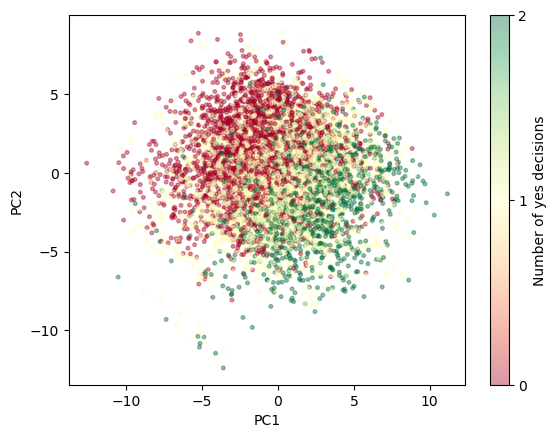

In [45]:
labels['decision'] = labels['decision'].replace({"b'1'": 1, "b'0'": 0})
labels['decision_o'] = labels['decision_o'].replace({"b'1'": 1, "b'0'": 0})

colors = labels['decision'].astype(int) + labels['decision_o'].astype(int)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=colors,
    cmap='RdYlGn',
    vmin=0,
    vmax=2,
    s=7,
    alpha=0.4
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(ticks=[0, 1, 2], label='Number of yes decisions')
plt.show()

TODO: Data preprocessing
Ideas:
Condense all the interest questions into one shared interest node? (Hidden node?)

TODO: Construct a "natural" BN
- We may introduce hidden nodes.

TODO: Run MLE on our BN to construct CPTs (use only ~85% of the data, reserve 15% for testing)
- If we decide to introduce hidden nodes, we will instead need to use EM to construct the CPTs.

TODO: Use the PC algorithm to construct a a BN, use MLE again to construct CPTs

TODO: Use PC algorithm again, this given only survey responses. How does it compare?

TODO: Is there any nice data visualization we can do?